# Regressão Linear Múltipla – Notas de Redação do ENEM
Objetivo: prever `NOTA_REDACAO` de uma escola a partir das notas das competências 2, 4 e 5.

In [1]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo de regressão e testes estatísticos
import statsmodels.formula.api as smf              # criar o modelo usando fórmulas (ex: 'y ~ x1 + x2')
import statsmodels.stats.api as sms                # testes estatísticos (ex: Breusch-Pagan)
import scipy.stats as stats                        # testes de normalidade (Shapiro, Q-Q plot)
from statsmodels.compat import lzip
from statsmodels.stats.outliers_influence import variance_inflation_factor  # cálculo do VIF
from statsmodels.tools.tools import add_constant   # adiciona a coluna de intercepto

In [2]:
enem = pd.read_csv('../dados/enem_tratado.csv', sep=',', encoding='iso-8859-1') #encoding iso-8859-1 evita erros com acentos

In [6]:
enem.head(10)

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,CO_ESCOLA,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,NaN,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
1,"1,90E+11",São Paulo,17,F,1,parda,1,2,privada,15567761.0,...,731.8,Inglês,1.0,160.0,120.0,200.0,200.0,200.0,880.0,Não
2,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,pública,35904958.0,...,393.2,Espanhol,1.0,80.0,160.0,120.0,100.0,100.0,560.0,Sim
3,"1,90E+11",Embu-Guaçu,17,F,1,parda,1,2,pública,NaN,...,419.2,Inglês,1.0,120.0,120.0,120.0,120.0,80.0,560.0,Sim
4,"1,90E+11",Guarulhos,23,F,1,branca,1,1,não_respondeu,NaN,...,796.1,Inglês,1.0,160.0,200.0,180.0,180.0,160.0,880.0,Sim
5,"1,90E+11",São José do Rio Preto,18,F,1,branca,1,2,pública,35028927.0,...,612.8,Espanhol,1.0,120.0,160.0,120.0,80.0,100.0,580.0,Não
6,"1,90E+11",Franca,32,M,1,parda,1,1,não_respondeu,NaN,...,584.1,Espanhol,1.0,120.0,120.0,120.0,120.0,100.0,580.0,Sim
7,"1,90E+11",Santo André,20,F,1,parda,1,1,não_respondeu,NaN,...,508.5,Espanhol,1.0,120.0,120.0,120.0,100.0,80.0,540.0,Sim
8,"1,90E+11",São Paulo,26,M,1,branca,1,1,não_respondeu,NaN,...,681.2,Espanhol,1.0,180.0,200.0,200.0,200.0,120.0,900.0,Sim
9,"1,90E+11",Santo André,44,F,2,parda,1,1,não_respondeu,NaN,...,488.1,Espanhol,1.0,120.0,120.0,120.0,120.0,40.0,520.0,Sim


In [7]:
enem.columns

Index(['NU_INSCRICAO', 'NO_MUNICIPIO_RESIDENCIA', 'IDADE', 'SEXO',
       'TP_ESTADO_CIVIL', 'RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO',
       'ESCOLA', 'CO_ESCOLA', 'NO_MUNICIPIO_ESC', 'TP_PRESENCA_CN',
       'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', 'NOTA_CN',
       'NOTA_CH', 'NOTA_LC', 'NOTA_MT', 'TP_LINGUA', 'TP_STATUS_REDACAO',
       'COMP1', 'COMP2', 'COMP3', 'COMP4', 'COMP5', 'NOTA_REDACAO',
       'INTERNET'],
      dtype='str')

In [8]:
enem.shape

(499940, 28)

In [ ]:
#Colocar duas casas decimais nos números
pd.options.display.float_format = '{:.2f}'.format

In [ ]:
# Estatísticas descritivas (média, desvio, mínimo, máximo, quartis)
enem.describe()

,IDADE,TP_ESTADO_CIVIL,TP_NACIONALIDADE,TP_ST_CONCLUSAO,CO_ESCOLA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NOTA_CN,NOTA_CH,NOTA_LC,NOTA_MT,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO
count,499940.00,499940.00,499940.00,499940.00,176894.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00,499940.00
mean,20.59,1.05,1.03,1.48,35211378.17,1.00,1.00,1.00,1.00,449.92,482.23,491.94,497.59,1.07,125.00,127.07,118.76,124.99,97.20,593.02
std,6.47,0.38,0.23,0.51,443039.20,0.00,0.00,0.00,0.00,152.98,161.12,156.25,183.47,0.58,28.63,39.85,36.78,33.88,57.79,170.54
min,12.00,0.00,0.00,1.00,11003065.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,17.00,1.00,1.00,1.00,35016251.00,1.00,1.00,1.00,1.00,412.40,450.60,490.10,427.90,1.00,120.00,120.00,100.00,120.00,60.00,500.00
50%,18.00,1.00,1.00,1.00,35044957.00,1.00,1.00,1.00,1.00,478.10,523.70,538.30,511.80,1.00,120.00,120.00,120.00,120.00,100.00,600.00
75%,21.00,1.00,1.00,2.00,35290701.00,1.00,1.00,1.00,1.00,544.40,578.10,576.20,617.90,1.00,140.00,140.00,140.00,140.00,140.00,680.00
max,91.00,4.00,4.00,4.00,53001036.00,1.00,1.00,1.00,1.00,860.90,822.70,772.30,984.70,9.00,200.00,200.00,200.00,200.00,200.00,1000.00


In [42]:
#escolher apenas uma escola (.copy() evita avisos ao criar novas colunas depois)
colegiox = enem.loc[enem.CO_ESCOLA == 35132287].copy()

In [ ]:
colegiox.isnull().sum() #verifica se há dados nulos 

NU_INSCRICAO               0
NO_MUNICIPIO_RESIDENCIA    0
IDADE                      0
SEXO                       0
TP_ESTADO_CIVIL            0
RACA                       0
TP_NACIONALIDADE           0
TP_ST_CONCLUSAO            0
ESCOLA                     0
CO_ESCOLA                  0
NO_MUNICIPIO_ESC           0
TP_PRESENCA_CN             0
TP_PRESENCA_CH             0
TP_PRESENCA_LC             0
TP_PRESENCA_MT             0
NOTA_CN                    0
NOTA_CH                    0
NOTA_LC                    0
NOTA_MT                    0
TP_LINGUA                  0
TP_STATUS_REDACAO          0
COMP1                      0
COMP2                      0
COMP3                      0
COMP4                      0
COMP5                      0
NOTA_REDACAO               0
INTERNET                   0
dtype: int64

In [14]:
colegiox.dtypes

NU_INSCRICAO                   str
NO_MUNICIPIO_RESIDENCIA        str
IDADE                        int64
SEXO                           str
TP_ESTADO_CIVIL              int64
RACA                           str
TP_NACIONALIDADE             int64
TP_ST_CONCLUSAO              int64
ESCOLA                         str
CO_ESCOLA                  float64
NO_MUNICIPIO_ESC               str
TP_PRESENCA_CN               int64
TP_PRESENCA_CH               int64
TP_PRESENCA_LC               int64
TP_PRESENCA_MT               int64
NOTA_CN                    float64
NOTA_CH                    float64
NOTA_LC                    float64
NOTA_MT                    float64
TP_LINGUA                      str
TP_STATUS_REDACAO          float64
COMP1                      float64
COMP2                      float64
COMP3                      float64
COMP4                      float64
COMP5                      float64
NOTA_REDACAO               float64
INTERNET                       str
dtype: object

In [ ]:
# Seleciona só as variáveis do estudo: a resposta (NOTA_REDACAO) e as explicativas (COMP2, COMP4, COMP5)
variaveis = colegiox[['NOTA_REDACAO', 'COMP2', 'COMP4', 'COMP5']]

# Análise exploratória 

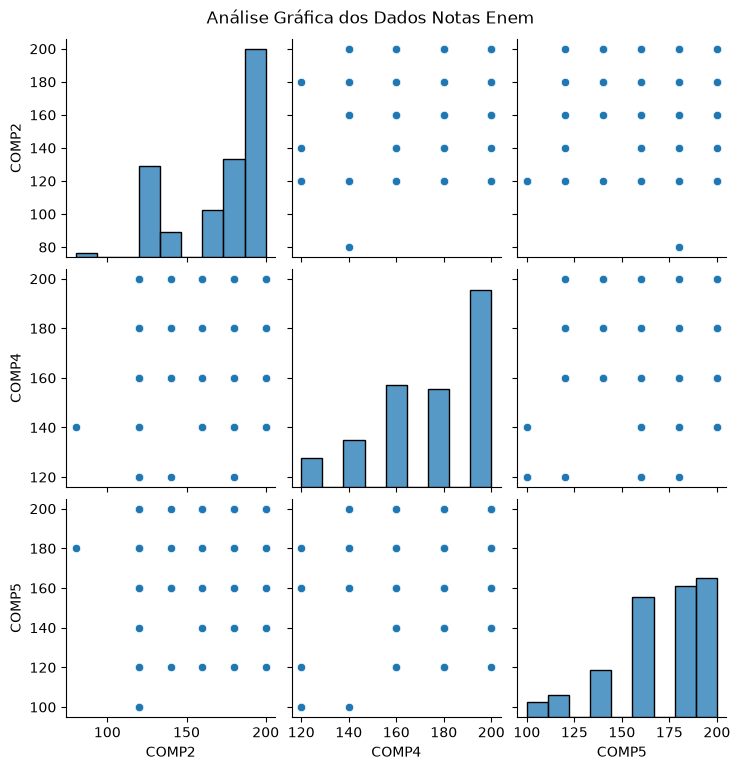

In [44]:
# Gráficos de dispersão entre todas as variáveis, para ver se há relação linear
sns.pairplot(variaveis)
plt.suptitle("Análise Gráfica dos Dados Notas Enem", y=1.02)
plt.show()

In [45]:
# Tabela de correlação (de -1 a 1)
variaveis.corr()

,COMP2,COMP4,COMP5
COMP2,1.00,0.38,0.30
COMP4,0.38,1.00,0.43
COMP5,0.30,0.43,1.00


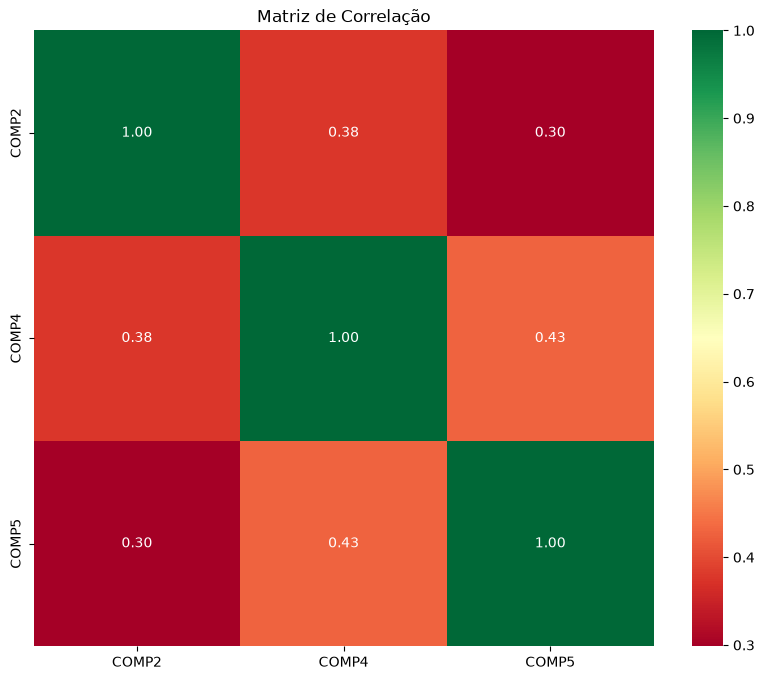

In [47]:
# Mesma correlação em formato de mapa de calor
correlation_matrix = variaveis.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Matriz de Correlação")
plt.show()

# Ajuste do modelo

In [48]:
# Regressão linear múltipla (OLS): variável resposta ~ variáveis explicativas
modelo = smf.ols('NOTA_REDACAO ~ COMP2 + COMP4 + COMP5', data = colegiox).fit()

In [49]:
# Resíduos = valor real - valor previsto
residuos = modelo.resid
residuos

17        -4.50
10760     33.31
13315     -5.72
20006    -26.43
26697      1.35
          ...  
426829    35.76
428241   -17.68
443242   -17.50
462446   -56.78
483420    34.53
Length: 130, dtype: float64

# Verificação dos Pressupostos

In [50]:
# Teste de Shapiro-Wilk: p-valor > 0,05 -> resíduos seguem distribuição normal
estatistica, p = stats.shapiro(residuos)
print('Estatística de teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatística de teste: 0.9847339466788405
p-valor: 0.15435337256144943


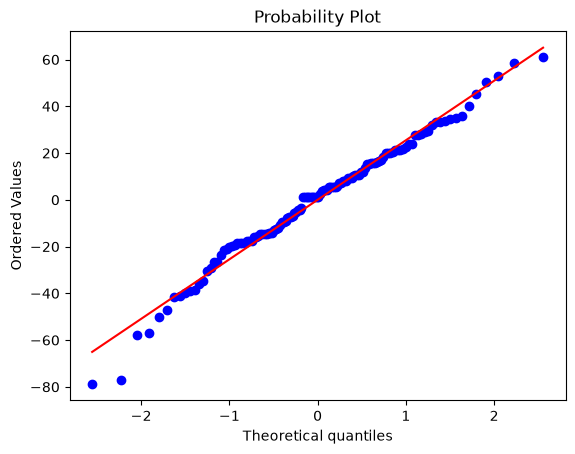

In [51]:
# Gráfico Q-Q: pontos próximos da reta indicam normalidade
stats.probplot(residuos, dist='norm', plot=plt)
plt.show()

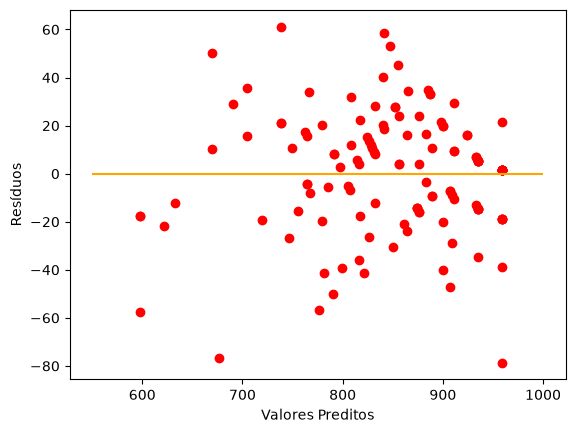

In [52]:
# Resíduos x valores preditos: o ideal é uma nuvem sem formato de funil
# (xmin e xmax da linha em zero devem cobrir o intervalo dos valores preditos)
plt.scatter(y=residuos, x=modelo.predict(), color='red')
plt.hlines(y=0, xmin=550, xmax=1000, color='orange')
plt.ylabel('Resíduos')
plt.xlabel('Valores Preditos')
plt.show()

In [ ]:
# Teste de Breusch-Pagan: p-valor > 0,05 -> variância constante (homocedasticidade)
estatistica, p, f, fp = sms.het_breuschpagan(modelo.resid, modelo.model.exog)
print('Estatística de teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatística de teste: 7.939832568694287
p-valor: 0.04727168987447238


In [53]:
# Resíduos estudentizados de cada observação (valores muito altos/baixos indicam outliers)
outliers = modelo.outlier_test()

In [33]:
outliers.max()

student_resid   2.47
unadj_p         0.96
bonf(p)         1.00
dtype: float64

In [34]:
outliers.min()

student_resid   -3.26
unadj_p          0.00
bonf(p)          0.19
dtype: float64

In [54]:
# Correlação apenas entre as variáveis explicativas (valores muito altos indicam redundância)
variaveis = colegiox[['COMP2', 'COMP4', 'COMP5']]
correlacoes = variaveis.corr()
correlacoes

,COMP2,COMP4,COMP5
COMP2,1.00,0.38,0.30
COMP4,0.38,1.00,0.43
COMP5,0.30,0.43,1.00


In [55]:
# VIF (Fator de Inflação da Variância): valores acima de 5 ou 10 indicam multicolinearidade
# add_constant: a função do VIF espera a coluna de intercepto nas variáveis explicativas
vif = add_constant(variaveis) # função espera a presença de uma constante na matriz de variáveis ​​explicativas
pd.Series([variance_inflation_factor(vif.values, j) for j in range(vif.shape[1])], index=vif.columns)

const   1.00
COMP2   1.20
COMP4   1.34
COMP5   1.26
dtype: float64

In [39]:
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:           NOTA_REDACAO   R-squared:                       0.924
Model:                            OLS   Adj. R-squared:                  0.922
Method:                 Least Squares   F-statistic:                     507.2
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           3.97e-70
Time:                        08:59:43   Log-Likelihood:                -604.30
No. Observations:                 130   AIC:                             1217.
Df Residuals:                     126   BIC:                             1228.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    116.1987     19.162      6.064      0.0

In [56]:
# Guarda os valores previstos pelo modelo para comparar com a nota real
colegiox['previsao'] = modelo.fittedvalues
colegiox.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,CO_ESCOLA,...,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET,previsao
17,"1,90E+11",São Paulo,18,F,1,branca,1,2,privada,35132287.00,...,Inglês,1.00,160.00,140.00,140.00,160.00,160.00,760.00,Sim,764.50
10760,"1,90E+11",São Paulo,17,M,1,parda,1,2,privada,35132287.00,...,Inglês,1.00,180.00,200.00,200.00,200.00,140.00,920.00,Sim,886.69
13315,"1,90E+11",São Paulo,17,F,1,branca,1,2,privada,35132287.00,...,Inglês,1.00,160.00,140.00,160.00,200.00,120.00,780.00,Sim,785.72
20006,"1,90E+11",São Paulo,17,F,1,branca,1,2,privada,35132287.00,...,Inglês,1.00,140.00,180.00,160.00,180.00,140.00,800.00,Sim,826.43
26697,"1,90E+11",São Paulo,18,F,1,branca,1,2,privada,35132287.00,...,Inglês,1.00,160.00,200.00,200.00,200.00,200.00,960.00,Sim,958.65
